# IEEE-CIS Fraud Detection: Exploratory Data Analysis
## DSCI 598 Capstone, Week 3
### Ben Miller

Companion notebook: `bm-fraud-baseline-models` (baseline models and the first competition submission).

# Part 1: Explore the data
> Perform exploratory data analysis to explore the structure of the data. This analysis could include examining variable distributions and the relationships between them. Consider calculating summary statistics and grouped aggregations. You might also include data visualizations that highlight interesting patterns in the data.

### Imports, seeds and constants

In [31]:
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

# Kaggle mounts the competition files here (read-only)
DATA_DIR = '/kaggle/input/competitions/ieee-fraud-detection'

# Column names used throughout
ID_COLUMN = 'TransactionID'
TARGET = 'isFraud'
TIME_COLUMN = 'TransactionDT'      # seconds from an undisclosed starting point, not a real timestamp
AMOUNT_COLUMN = 'TransactionAmt'

SECONDS_PER_DAY = 24 * 60 * 60

# EDA settings
TOP_N_CATEGORIES = 10              # categories shown per chart; the rest are rare
CATEGORY_COLUMNS = ['ProductCD', 'card4', 'card6', 'P_emaildomain', 'DeviceType', 'M4']
CORRELATION_SAMPLE_SIZE = 50_000   # rows sampled for V-column correlations; all 590k rows is slow
HIGH_CORRELATION = 0.95            # V-column pairs above this are near-duplicates

HIGH_CARDINALITY_COLUMNS = ['card1', 'card2', 'addr1', 'P_emaildomain', 'R_emaildomain', 'DeviceInfo']

sns.set_theme(style='whitegrid')

### Data-loading functions

The competition splits each transaction across two files: `*_transaction.csv` (every transaction) and `*_identity.csv` (device and network details, for only some transactions). These functions load both, fix a column-name mismatch in the test identity file, and join them.

In [32]:
def downcast_numeric_columns(frame):
    """
    Shrink float64 columns to float32 and integer columns to the smallest type that fits.
    The raw tables need several GB as float64; float32 roughly halves that, and tree
    models don't need the extra precision.
    """
    smaller_types = {}
    for column in frame.columns:
        if pd.api.types.is_float_dtype(frame[column]):
            smaller_types[column] = 'float32'
        elif pd.api.types.is_integer_dtype(frame[column]):
            smallest_fit = pd.to_numeric(frame[column], downcast='integer')
            smaller_types[column] = smallest_fit.dtype

    # one astype call for every column; assigning hundreds of columns one at a time fragments the DataFrame
    return frame.astype(smaller_types)


def standardize_identity_columns(identity):
    """
    Rename test_identity's 'id-01' style columns to train's 'id_01' spelling.
    The competition files use a hyphen in test and an underscore in train, so without
    this every identity feature would silently be missing in test after the merge.
    """
    renamed_columns = {}
    for column in identity.columns:
        if column.startswith('id-'):
            renamed_columns[column] = column.replace('id-', 'id_')
    return identity.rename(columns=renamed_columns)


def load_table(file_name):
    """One competition CSV, with its numeric columns downcast."""
    frame = pd.read_csv(os.path.join(DATA_DIR, file_name))
    return downcast_numeric_columns(frame)


def merge_identity(transactions, identity):
    """
    Left-join identity onto transactions by TransactionID, and flag which rows had a match.
    Only some transactions have identity data, so a left join keeps every transaction and
    leaves the identity columns missing for the rest.
    """
    # mark identity rows before the merge; transactions without a match end up missing, then 0
    flagged_identity = identity.assign(has_identity=1)
    merged = transactions.merge(flagged_identity, on=ID_COLUMN, how='left')
    merged['has_identity'] = merged['has_identity'].fillna(0).astype('int8')
    return merged


def load_split(split_name):
    """The merged transaction + identity table for 'train' or 'test'."""
    transactions = load_table(f'{split_name}_transaction.csv')
    identity = standardize_identity_columns(load_table(f'{split_name}_identity.csv'))
    return merge_identity(transactions, identity)


def memory_mb(frame):
    """How much memory a DataFrame uses, in megabytes."""
    return frame.memory_usage(deep=True).sum() / 1024 ** 2

### Load and merge train and test

In [33]:
train = load_split('train')
test = load_split('test')

print(f'train: {train.shape[0]:,} rows x {train.shape[1]} columns, {memory_mb(train):,.0f} MB')
print(f'test:  {test.shape[0]:,} rows x {test.shape[1]} columns, {memory_mb(test):,.0f} MB')

# test has no isFraud column, so every other column should match train's
missing_from_test = set(train.columns) - set(test.columns) - {TARGET}
print('columns in train but not test:', sorted(missing_from_test) if missing_from_test else 'none')

train: 590,540 rows x 435 columns, 1,604 MB
test:  506,691 rows x 434 columns, 1,387 MB
columns in train but not test: none


### Target balance

How rare fraud is decides how the model has to be scored.

In [34]:
fraud_count = int(train[TARGET].sum())
fraud_rate = train[TARGET].mean()

print(f'{fraud_count:,} of {len(train):,} training transactions are fraud ({fraud_rate:.2%})')
print(f'Always predicting "not fraud" would be {1 - fraud_rate:.2%} accurate, which is why the '
      'competition is scored on ROC AUC instead of accuracy.')

20,663 of 590,540 training transactions are fraud (3.50%)
Always predicting "not fraud" would be 96.50% accurate, which is why the competition is scored on ROC AUC instead of accuracy.


### Train and test over time

`TransactionDT` is seconds from an undisclosed start, so dividing by 86,400 gives a day number. This shows whether test comes from the same period as train or after it, which decides how to validate models.

train covers days 1-182
test covers days  213-395
gap between the end of train and the start of test: 31 days


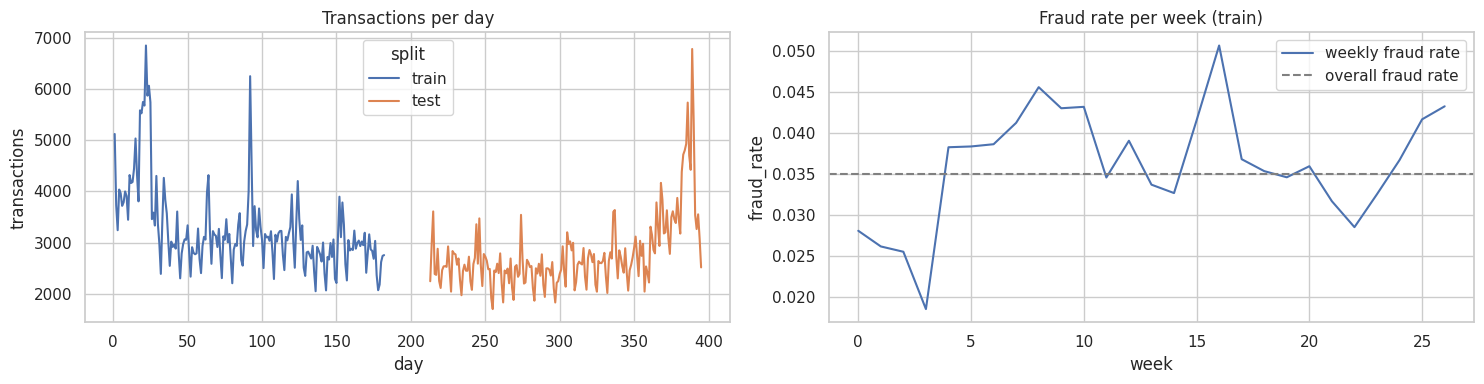

In [35]:
def day_numbers(frame):
    """The day each transaction happened on, counting from the dataset's starting point."""
    return frame[TIME_COLUMN] // SECONDS_PER_DAY


def transactions_per_day(frame, split_name):
    """Transaction counts per day, labeled with the split name so train and test can share one chart."""
    counts = day_numbers(frame).value_counts().sort_index()
    return pd.DataFrame({'day': counts.index, 'transactions': counts.values, 'split': split_name})


def fraud_rate_per_week(frame):
    """Share of transactions that are fraud in each week of the training period."""
    weeks = day_numbers(frame) // 7
    weekly = frame.groupby(weeks)[TARGET].mean()
    return pd.DataFrame({'week': weekly.index, 'fraud_rate': weekly.values})


train_days = day_numbers(train)
test_days = day_numbers(test)
print(f'train covers days {train_days.min()}-{train_days.max()}')
print(f'test covers days  {test_days.min()}-{test_days.max()}')
print(f'gap between the end of train and the start of test: {test_days.min() - train_days.max()} days')

daily_counts = pd.concat([transactions_per_day(train, 'train'), transactions_per_day(test, 'test')])
weekly_fraud = fraud_rate_per_week(train)

figure, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.lineplot(x='day', y='transactions', hue='split', data=daily_counts, ax=axes[0])
axes[0].set_title('Transactions per day')
sns.lineplot(x='week', y='fraud_rate', data=weekly_fraud, ax=axes[1], label='weekly fraud rate')
axes[1].axhline(fraud_rate, linestyle='--', color='gray', label='overall fraud rate')
axes[1].set_title('Fraud rate per week (train)')
axes[1].legend()
plt.tight_layout()
plt.show()

### Transaction amount

Amounts are heavily skewed, so the histogram uses a log scale. `common_norm=False` scales each class separately, so the small fraud class is still visible.

TransactionAmt by class:
            count    mean     std   min    25%   50%    75%       max
isFraud                                                              
0        569877.0  134.51  239.40  0.25  43.97  68.5  120.0  31937.39
1         20663.0  149.24  232.21  0.29  35.04  75.0  161.0   5191.00


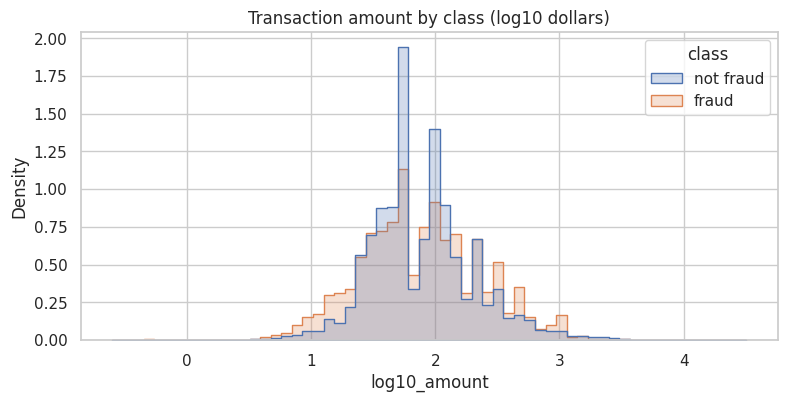

In [36]:
print('TransactionAmt by class:')
print(train.groupby(TARGET)[AMOUNT_COLUMN].describe().round(2).to_string())

amount_frame = pd.DataFrame({
    'log10_amount': np.log10(train[AMOUNT_COLUMN]),
    'class': train[TARGET].map({0: 'not fraud', 1: 'fraud'}),
})
plt.figure(figsize=(9, 4))
sns.histplot(x='log10_amount', hue='class', data=amount_frame, stat='density',
             common_norm=False, bins=60, element='step')
plt.title('Transaction amount by class (log10 dollars)')
plt.show()

### Fraud rate by category

Fraud rate and volume for the most common values of a few categorical columns. Missing values count as their own category, since whether a field is blank can itself be a signal.

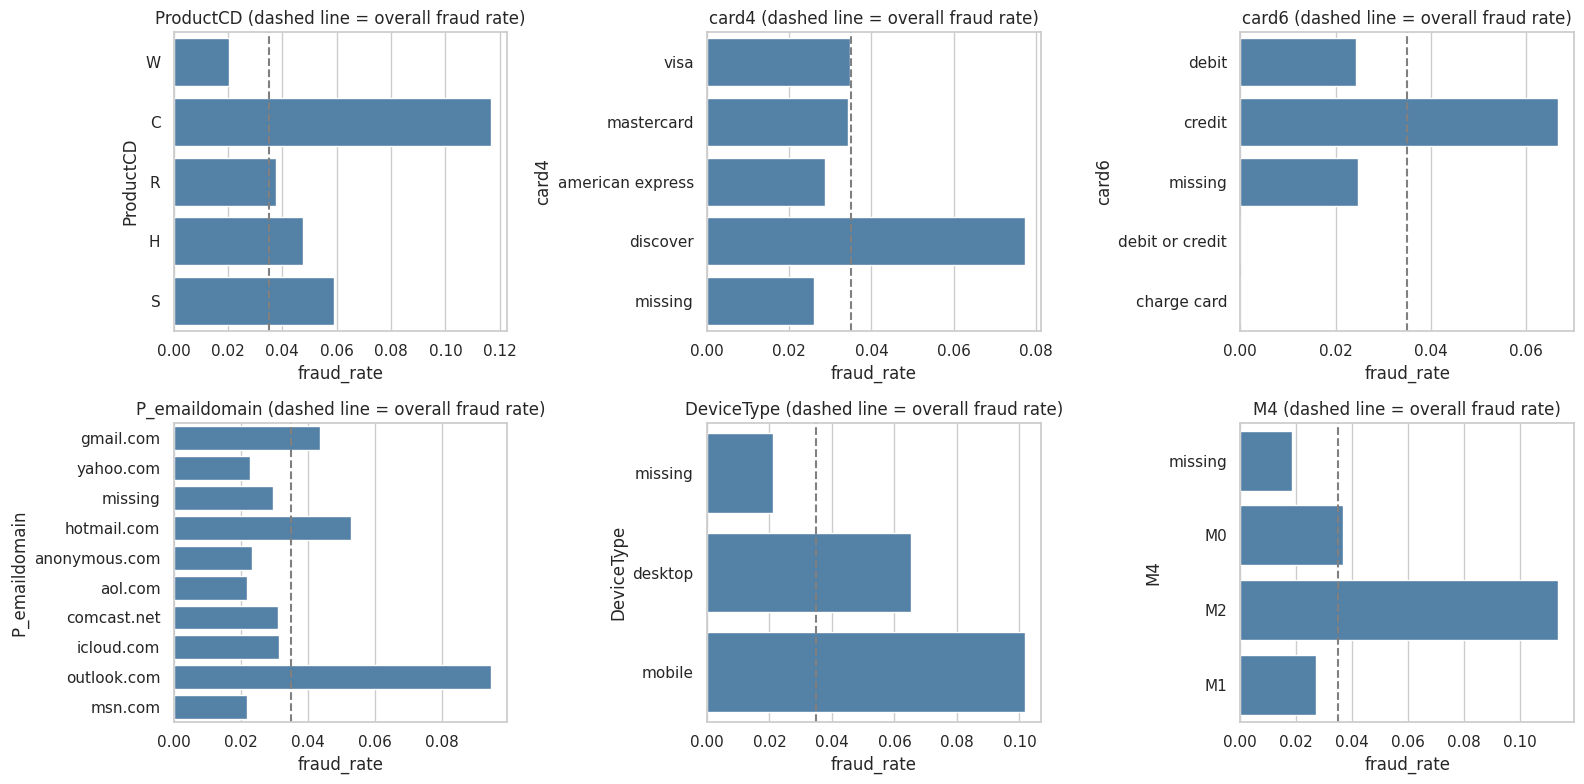

           fraud_rate  transactions
ProductCD                          
W              0.0204        439670
C              0.1169         68519
R              0.0378         37699
H              0.0477         33024
S              0.0590         11628


In [37]:
def fraud_rate_by_category(frame, column, top_n):
    """Fraud rate and transaction count for the top_n most common values of one column."""
    is_missing = frame[column].isna()
    categories = frame[column].astype(str)
    categories[is_missing] = 'missing'
    grouped = frame[TARGET].groupby(categories)
    summary = pd.DataFrame({'fraud_rate': grouped.mean(), 'transactions': grouped.size()})
    return summary.sort_values('transactions', ascending=False).head(top_n)


figure, axes = plt.subplots(2, 3, figsize=(16, 8))
for axis, column in zip(axes.flatten(), CATEGORY_COLUMNS):
    summary = fraud_rate_by_category(train, column, TOP_N_CATEGORIES).reset_index()
    summary[column] = summary[column].astype(str)
    sns.barplot(x='fraud_rate', y=column, data=summary, ax=axis, color='steelblue')
    axis.axvline(fraud_rate, linestyle='--', color='gray')
    axis.set_title(f'{column} (dashed line = overall fraud rate)')
plt.tight_layout()
plt.show()

print(fraud_rate_by_category(train, 'ProductCD', TOP_N_CATEGORIES).round(4).to_string())

### Identity coverage

Only some transactions have a row in the identity file. This checks how many, and whether those transactions behave differently.

In [38]:
print(f"train transactions with identity data: {train['has_identity'].mean():.1%}")
print(f"test transactions with identity data:  {test['has_identity'].mean():.1%}")
print()
print(fraud_rate_by_category(train, 'has_identity', 2).round(4).to_string())

train transactions with identity data: 24.4%
test transactions with identity data:  28.0%

              fraud_rate  transactions
has_identity                          
0                 0.0209        446307
1                 0.0785        144233


### Missing values by column group

The columns come in anonymized families (C, D, M, V, id, card and so on). Summarizing missingness per family is easier to read than 430 separate columns.

       columns  mean_missing_share  columns_over_90pct_missing
id          38               0.848                          10
dist         2               0.766                           1
D           15               0.582                           1
M            9               0.499                           0
V          339               0.430                           0
other       10               0.249                           0
addr         2               0.111                           0
card         6               0.005                           0
C           14               0.000                           0


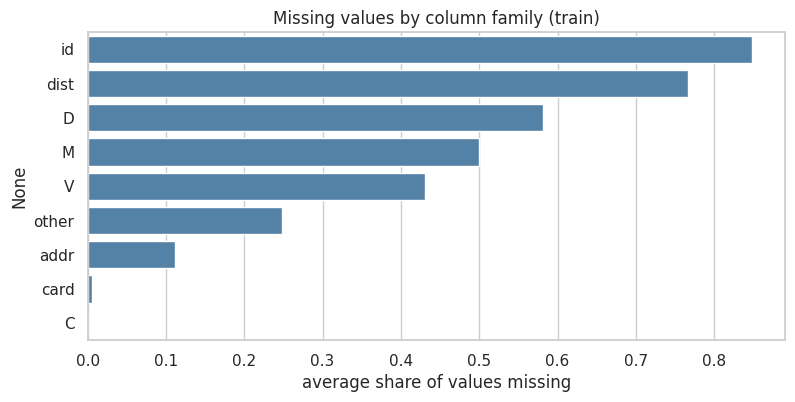

In [39]:
def column_group(column):
    """The feature family a column belongs to, from its name: 'V' for V1-V339, 'id' for id_01-id_38, and so on."""
    if column.startswith('id_'):
        return 'id'
    if column.startswith('card'):
        return 'card'
    prefix = column.rstrip('0123456789')  # 'V258' -> 'V', 'addr1' -> 'addr'
    if prefix in ['C', 'D', 'M', 'V', 'addr', 'dist']:
        return prefix
    return 'other'


def count_mostly_missing(missing_shares):
    """How many columns in a group are more than 90% missing."""
    return int((missing_shares > 0.9).sum())


def missing_share_by_group(frame):
    """Per column family: how many columns, their average share of missing values, and how many are over 90% missing."""
    missing_share = frame.isna().mean()
    groups = missing_share.index.map(column_group)
    grouped = missing_share.groupby(groups)
    summary = pd.DataFrame({
        'columns': grouped.size(),
        'mean_missing_share': grouped.mean(),
        'columns_over_90pct_missing': grouped.apply(count_mostly_missing),
    })
    return summary.sort_values('mean_missing_share', ascending=False)


missing_summary = missing_share_by_group(train)
print(missing_summary.round(3).to_string())

plt.figure(figsize=(9, 4))
sns.barplot(x=missing_summary['mean_missing_share'], y=missing_summary.index, color='steelblue')
plt.xlabel('average share of values missing')
plt.title('Missing values by column family (train)')
plt.show()

### Redundancy in the V columns

The 339 V columns are engineered by Vesta and anonymized. If many pairs are nearly identical, the model is carrying a lot of duplicate information. Correlations are computed on a sample of rows to keep this fast.

In [40]:
def count_highly_correlated_pairs(frame, columns, threshold):
    """How many column pairs have an absolute correlation above threshold, counting each pair once."""
    correlation = frame[columns].corr().abs()
    upper_triangle = np.triu(np.ones(correlation.shape, dtype=bool), k=1)  # each pair once, no self-pairs
    pair_correlations = correlation.where(upper_triangle).stack()
    return int((pair_correlations > threshold).sum())


v_columns = []
for column in train.columns:
    if column_group(column) == 'V':
        v_columns.append(column)

sample_size = min(CORRELATION_SAMPLE_SIZE, len(train))
v_sample = train[v_columns].sample(n=sample_size, random_state=SEED)
high_pairs = count_highly_correlated_pairs(v_sample, v_columns, HIGH_CORRELATION)
total_pairs = len(v_columns) * (len(v_columns) - 1) // 2
print(f'{high_pairs:,} of {total_pairs:,} V-column pairs have |correlation| > {HIGH_CORRELATION}')

634 of 57,291 V-column pairs have |correlation| > 0.95


### Distinct values in high-cardinality columns

In [41]:
distinct_counts = train[HIGH_CARDINALITY_COLUMNS].nunique().sort_values(ascending=False)
print(distinct_counts.to_string())

card1            13553
DeviceInfo        1786
card2              500
addr1              332
R_emaildomain       60
P_emaildomain       59


# Part 2: Technical challenges
> Start identifying the technical challenges associated with working with the dataset for your competition. Begin considering how to address these challenges.

### Challenges found, and how I'll handle them

Each challenge points to the output above that shows it.

| Challenge | Evidence above | How I'll handle it |
|---|---|---|
| **Size.** 590,540 training rows and 435 columns after merging identity, using 1.6 GB in memory even after downcasting (test adds 1.4 GB). | Load cell | Downcast numbers to float32 when loading. Next week, drop redundant V columns. |
| **Rare positives.** 20,663 of 590,540 transactions (3.50%) are fraud, so always predicting "not fraud" would be 96.50% accurate. | Target balance | Score with ROC AUC, the competition metric, never accuracy. |
| **Test comes after train in time.** Train covers days 1–182 and test covers days 213–395, a 31-day gap. The weekly fraud rate also moves between about 2% and 5%. | Train and test over time | Validate on the most recent slice of train, not a random split, and don't feed raw `TransactionDT` to the model. |
| **Identity data covers only some transactions.** 24.4% of train and 28.0% of test have identity rows, and those transactions are fraud 7.85% of the time vs. 2.09% without. Test's identity file also spells its columns `id-01` instead of `id_01`. | Identity coverage; "columns in train but not test: none" in the load cell confirms the rename worked | Left join, rename test's columns, and keep `has_identity` as a feature, since having identity data is itself a strong fraud signal. |
| **Heavy missingness.** The id columns are 85% missing on average (10 of 38 are over 90% missing), dist columns 77%, D columns 58% and V columns 43%. | Missing values by column group | Gradient-boosted trees handle missing values natively. Missingness itself may be a signal. |
| **Redundant anonymized features.** 634 of 57,291 V-column pairs have an absolute correlation above 0.95, measured on a 50,000-row sample. | Redundancy in the V columns | Next week: keep one column per highly correlated group and check whether validation AUC holds. |
| **Masked meanings and many distinct values.** Column meanings are hidden, and columns like `card1`, `P_emaildomain` and `DeviceInfo` have many distinct values. | Distinct values in high-cardinality columns | Integer-encode for trees now. Later, try frequency encoding and grouping transactions by card and address to approximate a customer ID. |